# 03 · Origin replay, integrity checks and baselines
## Summary
All baselines share one origin–delivery feature store and fallback policy. Forecasts are saved before their outcomes are joined for scoring. RTE is a **provided-column retrospective proxy**, never an authenticated historical forecast vintage.
## Context and methods
Each origin forecasts the complete following local day. Training/evaluation splits keep origin groups intact. Demand observations are assumed available at interval end plus two hours; weekly matching uses local wall time. Both occurrences of a repeated source hour are averaged; absent source hours invoke the declared fallback. These rules are tested below.

Validation: 2023-07-01–2025-06-30. Test remains outside this notebook. Reference: [rolling-origin evaluation](https://otexts.com/fpp3/tscv.html).

In [1]:
%matplotlib inline
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "config/forecast_contract.json").exists())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.common import load_contract, prepare_directories, plotting_style, write_json, fingerprint
contract = load_contract(ROOT)
prepare_directories(ROOT)
plotting_style()
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_rows", 16)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

### 1. Run behavioral integrity tests

In [2]:
import unittest
suite=unittest.defaultTestLoader.discover(str(ROOT/"tests"))
test_result=unittest.TextTestRunner(verbosity=1).run(suite)
assert test_result.wasSuccessful(), "Integrity tests failed: stop the backtest."

.

.

.

.

.

...

.

.

.

.

----------------------------------------------------------------------
Ran 18 tests in 5.466s

OK


### 2. Reconstruct information at every historical origin

In [3]:
from src.data import read_audited, availability_gate
from src.features import build_supervised
data=read_audited(ROOT)
features,labels=build_supervised(data,contract,rte_mode="proxy")
features.to_csv(ROOT/"data/origin_snapshots/history_features.csv.gz",index=False,compression="gzip")
labels.to_csv(ROOT/"data/processed/evaluation_labels.csv.gz",index=False,compression="gzip")
write_json(ROOT/"data/origin_snapshots/manifest.json",{"contract_sha256":fingerprint(ROOT/"config/forecast_contract.json"),"rows":len(features),"origins":features.origin.nunique(),"regime":"retrospective assumptions; no authentic forecast archives"})
display(features[["origin","delivery_time","lead_hours","week_lag_1","max_history_available_at","rte_version_status"]].head())
display(features.groupby("local_day").size().value_counts().rename_axis("delivery_intervals").to_frame("days"))
assert features.max_history_available_at.dropna().lt(features.loc[features.max_history_available_at.notna(),"origin"]).all()
display(availability_gate(ROOT,contract))

,origin,delivery_time,lead_hours,week_lag_1,max_history_available_at,rte_version_status
0,2019-02-04 10:00:00+00:00,2019-02-04 23:00:00+00:00,13.000,"73,540.000",2019-02-04 09:00:00+00:00,provided_column_assumed_at_cutoff_RETROSPECTIVE
1,2019-02-04 10:00:00+00:00,2019-02-05 00:00:00+00:00,14.000,"70,070.000",2019-02-04 09:00:00+00:00,provided_column_assumed_at_cutoff_RETROSPECTIVE
2,2019-02-04 10:00:00+00:00,2019-02-05 01:00:00+00:00,15.000,"69,286.000",2019-02-04 09:00:00+00:00,provided_column_assumed_at_cutoff_RETROSPECTIVE
3,2019-02-04 10:00:00+00:00,2019-02-05 02:00:00+00:00,16.000,"66,992.000",2019-02-04 09:00:00+00:00,provided_column_assumed_at_cutoff_RETROSPECTIVE
4,2019-02-04 10:00:00+00:00,2019-02-05 03:00:00+00:00,17.000,"65,804.000",2019-02-04 09:00:00+00:00,provided_column_assumed_at_cutoff_RETROSPECTIVE


,days
delivery_intervals,
24,2688
23,8
25,7


,source,nonempty_archive_with_schema,provenance_verified,operationally_usable,rows,interval_aggregation_verified,operational_experiment_enabled
0,demand,False,False,False,0,False,False
1,rte,False,False,False,0,False,False
2,weather,False,False,False,0,False,False


### 3. Replay four distinct baselines and save predictions

In [4]:
from src.backtest import baseline_replay
from src.metrics import scorecard,matched_scorecard,segment_scorecard
start=contract["validation_folds"][0]["start"]
end=contract["validation_folds"][-1]["end"]
baselines=baseline_replay(features,start,end,ROOT,contract)
policy_scores=scorecard(baselines,labels)
raw_scores=scorecard(baselines,labels,"raw_prediction_mw")
common_scores,common=matched_scorecard(baselines,labels,"raw_prediction_mw")
policy_scores.to_csv(ROOT/"reports/scorecards/baselines_validation_policy.csv",index=False)
raw_scores.to_csv(ROOT/"reports/scorecards/baselines_validation_raw_availability.csv",index=False)
common_scores.to_csv(ROOT/"reports/scorecards/baselines_validation_common.csv",index=False)
display(policy_scores); display(raw_scores); display(common_scores)

,model,eligible_targets,scored,missing_targets,availability,MAE_MW,RMSE_MW,bias_actual_minus_forecast_MW,WAPE_percent
0,seasonal_naive,"17,542.000","17,542.000",2.000,1.000,"3,371.030","4,935.033",34.201,6.732
1,comparable_days,"17,542.000","17,542.000",2.000,1.000,"3,735.523","5,231.522",58.836,7.460
2,rte_proxy,"17,542.000","17,542.000",2.000,1.000,"1,388.401","1,720.107","1,085.367",2.773
3,rte_bias_proxy,"17,542.000","17,542.000",2.000,1.000,"1,013.216","1,312.219",-0.738,2.023


,model,eligible_targets,scored,missing_targets,availability,MAE_MW,RMSE_MW,bias_actual_minus_forecast_MW,WAPE_percent
0,seasonal_naive,"17,542.000","17,540.000",2.000,1.000,"3,370.383","4,934.350",35.237,6.730
1,comparable_days,"17,542.000","17,542.000",2.000,1.000,"3,735.523","5,231.522",58.836,7.460
2,rte_proxy,"17,542.000","17,542.000",2.000,1.000,"1,388.401","1,720.107","1,085.367",2.773
3,rte_bias_proxy,"17,542.000","17,542.000",2.000,1.000,"1,013.216","1,312.219",-0.738,2.023


,model,eligible_targets,scored,missing_targets,availability,MAE_MW,RMSE_MW,bias_actual_minus_forecast_MW,WAPE_percent
0,seasonal_naive,"17,540.000","17,540.000",0.000,1.000,"3,370.383","4,934.350",35.237,6.730
1,comparable_days,"17,540.000","17,540.000",0.000,1.000,"3,734.918","5,230.912",59.874,7.458
2,rte_proxy,"17,540.000","17,540.000",0.000,1.000,"1,388.471","1,720.178","1,085.402",2.773
3,rte_bias_proxy,"17,540.000","17,540.000",0.000,1.000,"1,013.287","1,312.282",-0.693,2.023


### 4. Common observations and fallback accounting

,predictions,fallbacks
model,,
comparable_days,17544,0
rte_bias_proxy,17544,2
rte_proxy,17544,2
seasonal_naive,17544,2


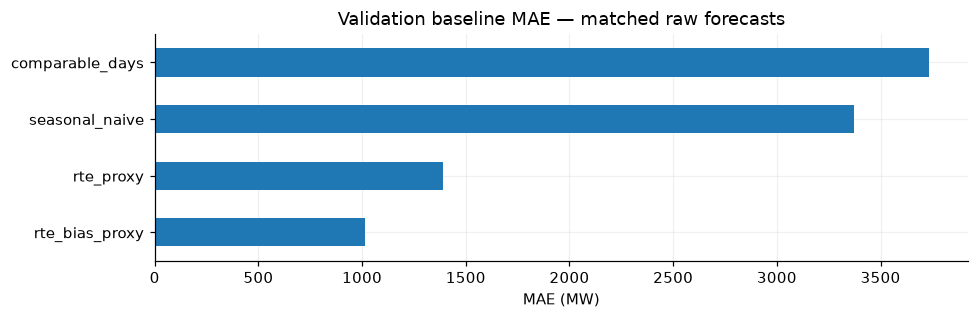

In [5]:
display(baselines.groupby("model").agg(predictions=("prediction_mw","count"),fallbacks=("fallback_used","sum")))
fig,ax=plt.subplots(figsize=(9,3))
common_scores.set_index("model").MAE_MW.sort_values().plot.barh(ax=ax)
ax.set(title="Validation baseline MAE — matched raw forecasts",xlabel="MAE (MW)",ylabel="")
plt.tight_layout(); plt.show()

## Takeaways
Weekly persistence, comparable-day smoothing, provided RTE and trailing RTE-bias adjustment answer different questions. Compare common raw forecasts and the complete fallback policy separately. Missing targets are unscored, counted and never interpolated. Missing inputs cannot improve scores simply by removing difficult days. Operational RTE and weather comparisons remain gated.